# Tutorial: predict unmeasured genes in a fetal-heart MERFISH section

This notebook runs RESONATE from start to finish on a small public dataset. It downloads the data, looks at the inputs,
fits the model on a CPU, checks the predictions against measured genes that were hidden from the model, predicts genes
that the spatial panel did not measure, and plots the results.

The outputs and figures on this page come from one run of this notebook, top to bottom, in a new environment on 4 CPU
cores. To run it yourself, download the notebook (the download button at the top of this page, or
[from GitHub](https://github.com/J041120h/RESONATE_tutorial/blob/main/docs/tutorials/walkthrough.ipynb)) into an empty
folder and run all cells.

**Before you start**

* Install RESONATE with the notebook extras ([Installation](https://j041120h.github.io/RESONATE_tutorial/installation/)):

  ```bash
  pip install torch --index-url https://download.pytorch.org/whl/cpu
  pip install "resonate-st[notebook] @ git+https://github.com/J041120h/RESONATE.git"
  ```

* The run on this page took 8 minutes on 4 CPU cores (`prepare` 0.7 min, `fit` 6.3 min) and used at most 8.9 GiB of
  memory. Use a machine with at least 16 GB of RAM.
* The cell in step 1 runs `curl` and `sha256sum` in `bash` (Linux; on macOS replace `sha256sum -c` by
  `shasum -a 256 -c`).

**Steps**

1. Download the demo data
2. Look at the inputs
3. Prepare, fit and predict
4. Score the held-out genes
5. Measured and predicted maps
6. Predict genes outside the panel
7. Predicted expression by cell type
8. Save the results

## 1. Download the demo data

The demo data are in the [`sample_data/`](https://github.com/J041120h/RESONATE/tree/main/sample_data) folder of the code
repository (about 12 MB):

| file | content |
|---|---|
| `fetal_heart_spatial.h5ad` | MERFISH raw counts, 12,000 cells x 236 genes: a window of about 1.65 mm of a 13-week fetal-heart section |
| `fetal_heart_reference.h5ad` | single-cell RNA-seq reference of the same study, raw counts, 8,011 cells x 2,244 genes |
| `scgpt_spatial_embeddings_subset.npz` | the scGPT-spatial gene embedding (512 numbers) of each of the 2,244 reference genes |
| `held_out_genes.txt` | 48 panel genes that we hide from the model and use to score it |
| `sample_info.json`, `SHA256SUMS` | counts and checksums |

The next cell downloads the files into `data/` and checks them against `SHA256SUMS`.

In [1]:
%%bash
mkdir -p data
cd data
BASE=https://raw.githubusercontent.com/J041120h/RESONATE/main/sample_data
for f in fetal_heart_spatial.h5ad fetal_heart_reference.h5ad scgpt_spatial_embeddings_subset.npz \
         held_out_genes.txt sample_info.json SHA256SUMS; do
    curl -fsSLO "$BASE/$f"
done
sha256sum -c SHA256SUMS

fetal_heart_reference.h5ad: OK
fetal_heart_spatial.h5ad: OK
held_out_genes.txt: OK
sample_info.json: OK
scgpt_spatial_embeddings_subset.npz: OK


Every line should end in `OK`.

The MERFISH data and the reference are from Farah *et al.*, *Nature* 627, 854-864 (2024), released under CC0 1.0. The
embedding rows are copied from the scGPT-spatial model (Wang *et al.*, bioRxiv 2025), released under CC BY 4.0. Cite
both if you use these files.

## 2. Look at the inputs

RESONATE needs three inputs:

* the **spatial data**: raw counts of the measured genes and the cell coordinates;
* a **reference**: raw counts from single-cell RNA-seq of the same tissue, which measures the genes you want to predict;
* **gene embeddings**: one fixed vector per gene (here from the scGPT-spatial foundation model).

In [2]:
import time
from importlib.metadata import version

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from matplotlib.colors import LinearSegmentedColormap

import resonate

print({package: version(package) for package in ["resonate-st", "torch", "numpy", "anndata", "scanpy"]})
print("CPU threads used by torch:", torch.get_num_threads())

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 8})
TEAL = "#0b6f5d"
GREY = "#d5dadf"
RAMP = LinearSegmentedColormap.from_list("ramp", ["#eef2f3", "#9fdcc9", "#10b396", "#0b6f5d", "#0b3b35"])

{'resonate-st': '0.1.0', 'torch': '2.15.0+cpu', 'numpy': '1.26.4', 'anndata': '0.12.19', 'scanpy': '1.11.5'}
CPU threads used by torch: 4


In [3]:
spatial = ad.read_h5ad("data/fetal_heart_spatial.h5ad")
reference = ad.read_h5ad("data/fetal_heart_reference.h5ad")
emb = resonate.load_gene_embeddings("data/scgpt_spatial_embeddings_subset.npz")
held_out = open("data/held_out_genes.txt").read().split()

print(spatial, "\n")
print(reference, "\n")
print(f"gene embeddings: {len(emb)} genes x {emb.dim} dimensions")
print(f"held-out genes: {len(held_out)}, for example {held_out[:6]}")

AnnData object with n_obs × n_vars = 12000 × 236
    obs: 'section', 'stage', 'author_fine', 'split'
    obsm: 'spatial' 

AnnData object with n_obs × n_vars = 8011 × 2244
    obs: 'donor', 'author_label' 

gene embeddings: 2244 genes x 512 dimensions
held-out genes: 48, for example ['ABCC9', 'ADAMTS6', 'ADGRL1', 'ADGRL2', 'ADM', 'AGPS']


* `spatial.X` holds raw counts of the 236 panel genes; `obsm["spatial"]` holds the cell coordinates in micrometres.
  `obs["split"]` assigns each cell to training, validation or test; test cells are used only for scoring.
  `obs["author_fine"]` holds the cell types annotated by the study's authors. RESONATE does not use them; we use them
  only to read the plots.
* `reference.X` holds raw counts of 2,244 genes, including all 236 panel genes. `obs["donor"]` (four samples) is used
  for batch correction inside RESONATE; `obs["author_label"]` holds the authors' cell types.

In [4]:
spatial.obs.head()

,section,stage,author_fine,split
R78_4C12_210018,R78_4C12,13PCW,vCM-LV-Trabecular,train
R78_4C12_210025,R78_4C12,13PCW,vCM-LV-AV,train
R78_4C12_210031,R78_4C12,13PCW,vCM-LV-AV,train
R78_4C12_210041,R78_4C12,13PCW,vFibro,train
R78_4C12_210052,R78_4C12,13PCW,vFibro,train


In [5]:
panel = set(spatial.var_names)
print("panel genes in the reference:", sum(g in panel for g in reference.var_names), "of", spatial.n_vars)
print("reference genes outside the panel:", sum(g not in panel for g in reference.var_names))
print("spatial cells per split:", spatial.obs["split"].value_counts().to_dict())
print("reference cells per donor:", reference.obs["donor"].value_counts().to_dict())

panel genes in the reference: 236 of 236
reference genes outside the panel: 2008
spatial cells per split: {'train': 9600, 'val': 1265, 'test': 1135}
reference cells per donor: {'13PCW_rep1': 2415, '13PCW_rep2': 2178, '15PCW_rep1': 1869, '15PCW_rep2': 1549}


The spatial window is mostly ventricular. To read the maps later, we group the authors' cell types into eight groups
and show each group on the section. The 37 cells of other types (white blood cells, a few atrial cardiomyocytes) are
left out of the panels.

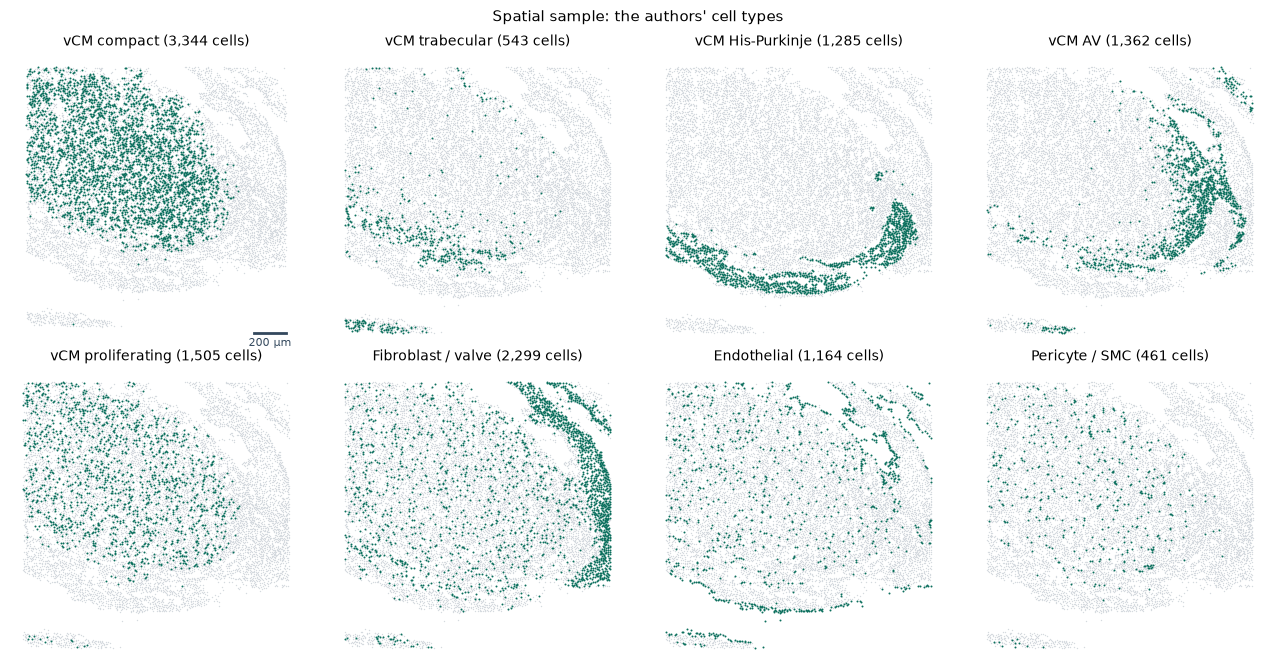

In [6]:
GROUPS = {
    "vCM compact": ["vCM-LV-Compact", "vCM-RV-Compact"],
    "vCM trabecular": ["vCM-LV-Trabecular", "vCM-RV-Trabecular"],
    "vCM His-Purkinje": ["vCM-His-Purkinje"],
    "vCM AV": ["vCM-LV-AV", "vCM-RV-AV"],
    "vCM proliferating": ["vCM-Proliferating"],
    "Fibroblast / valve": ["VIC", "vFibro", "aFibro", "EPDC"],
    "Endothelial": ["BEC", "VEC", "vEndocardial", "aEndocardial", "LEC"],
    "Pericyte / SMC": ["Pericyte", "VSMC"],
}
to_group = {label: group for group, labels in GROUPS.items() for label in labels}
group = spatial.obs["author_fine"].astype(str).map(to_group).fillna("Other")
spatial.obs["group"] = pd.Categorical(group, categories=list(GROUPS) + ["Other"])
xy = spatial.obsm["spatial"]


def clean(ax, scale_bar=False):
    ax.set_aspect("equal")
    ax.axis("off")
    if scale_bar:                                        # 200 micrometres, below the lower right corner
        x1, y0 = xy[:, 0].max(), xy[:, 1].min() - 40
        ax.plot([x1 - 200, x1], [y0, y0], color="#33485d", lw=2)
        ax.text(x1 - 100, y0 - 30, "200 µm", ha="center", va="top", fontsize=8, color="#33485d")


fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for k, (ax, name) in enumerate(zip(axes.ravel(), GROUPS)):
    m = (spatial.obs["group"] == name).to_numpy()
    ax.scatter(xy[~m, 0], xy[~m, 1], s=1.0, c=GREY, linewidths=0)
    ax.scatter(xy[m, 0], xy[m, 1], s=2.0, c=TEAL, linewidths=0)
    ax.set_title(f"{name} ({m.sum():,} cells)")
    clean(ax, scale_bar=(k == 0))
fig.suptitle("Spatial sample: the authors' cell types", fontsize=11)
fig.tight_layout()
plt.show()

For the reference, a UMAP of the normalised expression, coloured by the authors' cell types and by donor. The reference
contains atrial cardiomyocytes (`aCM`), which the spatial window does not. Within cell types, cells also group by donor;
RESONATE corrects for this (Harmony on `obs["donor"]`) when it clusters the reference.

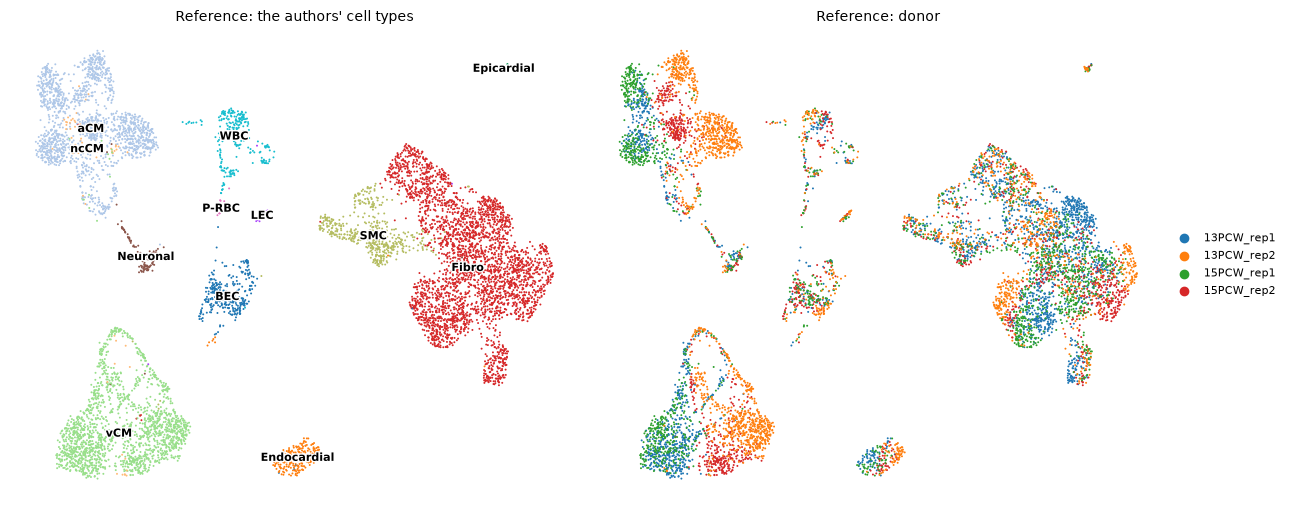

In [7]:
ref_log = reference.copy()
sc.pp.normalize_total(ref_log, target_sum=1e4)
sc.pp.log1p(ref_log)
sc.pp.pca(ref_log, n_comps=30, random_state=0)
sc.pp.neighbors(ref_log, random_state=0)
sc.tl.umap(ref_log, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sc.pl.umap(ref_log, color="author_label", ax=axes[0], show=False, legend_loc="on data", legend_fontsize=8,
           legend_fontoutline=2, frameon=False, title="Reference: the authors' cell types", size=8)
sc.pl.umap(ref_log, color="donor", ax=axes[1], show=False, frameon=False, title="Reference: donor", size=8)
fig.tight_layout()
plt.show()

## 3. Prepare, fit and predict

We first check the model on genes whose truth we know. `target_genes=held_out` names 48 genes that the panel measured.
`prepare` removes them from the spatial input before anything else and keeps their measured values aside, so the model
never sees them in any spatial cell. The reference still measures them, as it would measure any gene you want to
predict.

**Settings for a laptop CPU.** `resonate.Config()` holds the paper's settings. Here `device="cpu"` and
`tf32=False, attn_bf16=False` select plain float32 arithmetic on the CPU, and `max_epochs=12` caps each training stage at
12 epochs so that the run takes minutes. On a GPU, use `resonate.Config()` (see the [API reference](https://j041120h.github.io/RESONATE_tutorial/api/config/)).

`prepare` normalises the counts, smooths each cell's profile over similar cells, finds the 100 most similar reference
cells of every spatial cell, clusters the reference into cell types, gives every spatial cell a mixture over those types
and computes type-specific gene correlations in the reference. It prints its progress:

In [8]:
cfg = resonate.Config(device="cpu", tf32=False, attn_bf16=False, max_epochs=12)

t0 = time.time()
prep = resonate.prepare(spatial, reference, emb, target_genes=held_out, config=cfg)
print(prep)
print(f"prepare took {(time.time() - t0) / 60:.1f} min")

21:37:27 panel 236 genes = 188 measured + 48 targets (48 held out from the input)
21:37:27 12000 spatial cells (9600/1265/1135 train/val/test), 8011 reference cells, 4 reference batch(es), device cpu
21:37:28   lookup fold 1/20
21:37:29   lookup fold 2/20
21:37:29   lookup fold 3/20
21:37:30   lookup fold 4/20
21:37:30   lookup fold 5/20
21:37:30   lookup fold 6/20
21:37:31   lookup fold 7/20
21:37:31   lookup fold 8/20
21:37:32   lookup fold 9/20
21:37:32   lookup fold 10/20
21:37:32   lookup fold 11/20
21:37:33   lookup fold 12/20
21:37:33   lookup fold 13/20
21:37:34   lookup fold 14/20
21:37:34   lookup fold 15/20
21:37:34   lookup fold 16/20
21:37:35   lookup fold 17/20
21:37:35   lookup fold 18/20
21:37:36   lookup fold 19/20
21:37:36   lookup fold 20/20
21:37:36 reference cell types (Leiden on Harmony-corrected reference)
21:37:37   leiden resolution 1.0250 -> 24 clusters
21:37:37   leiden resolution 0.5375 -> 18 clusters
21:37:37 type-specific correlations
21:37:37 reference vo

The reference cell types are clusters of the reference (`L00`, `L01`, ...), found without labels:

In [9]:
print(dict(zip(prep.type_names, np.bincount(prep.ref_codes))))

{'L00': 1361, 'L01': 967, 'L02': 952, 'L03': 792, 'L04': 700, 'L05': 538, 'L06': 500, 'L07': 490, 'L08': 322, 'L09': 273, 'L10': 255, 'L11': 236, 'L12': 188, 'L13': 130, 'L14': 123, 'L15': 111, 'small': 73}


`fit` trains in two stages. **Stage 1** hides genes in reference cells and learns to reconstruct them, including the 48
held-out genes (the reference measures them). **Stage 2** continues on the spatial cells and reconstructs hidden
measured genes. During stage 2, 20 % of the input genes are set aside: their predictions in the validation cells choose
the checkpoint and the weight λ of the attention term. `train` is the training loss, `val` the validation score (higher
is better in stage 2).

In [10]:
t0 = time.time()
model = resonate.fit(prep, cfg)
print(f"fit took {(time.time() - t0) / 60:.1f} min")

21:38:11 [stage 1] 8011 reference cells (7209 train / 802 validation); lookup affine a=0.9987 b=-0.0012; mean warm-up loss 0.00007
21:38:27   [stage1_reference] epoch   1  train 1.79709  val 0.50594  (16s)
21:38:44   [stage1_reference] epoch   2  train 1.83719  val 0.50711  (17s)
21:38:58   [stage1_reference] epoch   3  train 1.84796  val 0.50854  (14s)
21:39:12   [stage1_reference] epoch   4  train 1.80048  val 0.50924  (14s)
21:39:25   [stage1_reference] epoch   5  train 1.76643  val 0.50940  (13s)
21:39:39   [stage1_reference] epoch   6  train 1.73048  val 0.51250  (14s)
21:39:52   [stage1_reference] epoch   7  train 1.70412  val 0.51399  (14s)
21:40:06   [stage1_reference] epoch   8  train 1.65781  val 0.51646  (13s)
21:40:19   [stage1_reference] epoch   9  train 1.90551  val 0.51796  (13s)
21:40:32   [stage1_reference] epoch  10  train 1.70906  val 0.52136  (13s)
21:40:46   [stage1_reference] epoch  11  train 1.70317  val 0.52379  (14s)
21:40:59   [stage1_reference] epoch  12  tra

The last line of the log is the choice of λ. On this small sample the set-aside genes score 0.3486 for every value of λ
(to four decimals), so the attention term changes the predictions very little here; the chosen value is λ = 1.

In [11]:
pred = model.predict()
pred

AnnData object with n_obs × n_vars = 12000 × 48
    obs: 'split'
    var: 'is_fit_target'
    uns: 'resonate'
    obsm: 'spatial'

`pred` is an AnnData with the same 12,000 cells, in the same order as `spatial`, and one column per target gene. The
values are on the model's log scale: `log1p` of counts normalised to the median library size of the input genes. They
are not counts.

## 4. Score the held-out genes

`score_heldout` compares the predictions with the measured values of the held-out genes in the **test cells**, which
were used neither for training nor for choosing the checkpoint. For each gene it computes the Pearson correlation across
test cells, then averages over genes. `top_n` is the score used in the paper: held-out genes detected in at least 10 %
of cells (at most 100 genes).

In [12]:
scores = resonate.score_heldout(prep, pred)
for name in ("top_n", "all_heldout"):
    s = scores[name]
    print(f"{name:12s} {s['n_genes']} genes, {s['n_cells']} test cells: "
          f"mean Pearson {s['pearson']:.3f}, mean Spearman {s['spearman']:.3f}")

top_n        47 genes, 1135 test cells: mean Pearson 0.384, mean Spearman 0.311
all_heldout  48 genes, 1135 test cells: mean Pearson 0.377, mean Spearman 0.305


In this run, the mean Pearson correlation over the 47 `top_n` genes is 0.384 (0.377 over all 48 held-out genes).
Numbers can differ slightly on other machines or with other library versions, for example through the clustering of the
reference.

In [13]:
truth_genes = [str(g) for g in prep.truth_genes]
detected = pd.Series((prep.truth_counts > 0).mean(0), index=truth_genes)

scored = [g for g in pred.var_names if g in detected.index]
per_gene = pd.DataFrame(scores["all_heldout"]["per_gene"], index=scored)[["pearson", "spearman"]]
per_gene["fraction of cells detected"] = detected[scored]
per_gene["in top_n"] = per_gene.index.isin(scores["top_n_genes"])
per_gene = per_gene.sort_values("pearson", ascending=False)

print("Pearson r over the 48 held-out genes:", per_gene["pearson"].describe()[["min", "25%", "50%", "75%", "max"]]
      .round(3).to_dict())
pd.concat([per_gene.head(5), per_gene.tail(5)]).round(3)

Pearson r over the 48 held-out genes: {'min': 0.002, '25%': 0.234, '50%': 0.388, '75%': 0.552, 'max': 0.762}


,pearson,spearman,fraction of cells detected,in top_n
FBLN2,0.762,0.614,0.303,True
IRX1,0.634,0.398,0.518,True
MECOM,0.618,0.456,0.256,True
PLK1,0.617,0.416,0.380,True
BMP2,0.614,0.458,0.218,True
CD24,0.118,0.103,0.220,True
TFF3,0.048,0.058,0.114,True
AGPS,0.033,0.071,0.169,True
IL1B,0.028,0.041,0.091,False
CTSV,0.002,0.083,0.169,True


Accuracy varies a lot between genes: from 0.002 (*CTSV*) to 0.762 (*FBLN2*), with a median of 0.388. *IL1B* is detected
in fewer than 10 % of the cells and is therefore not part of `top_n`.

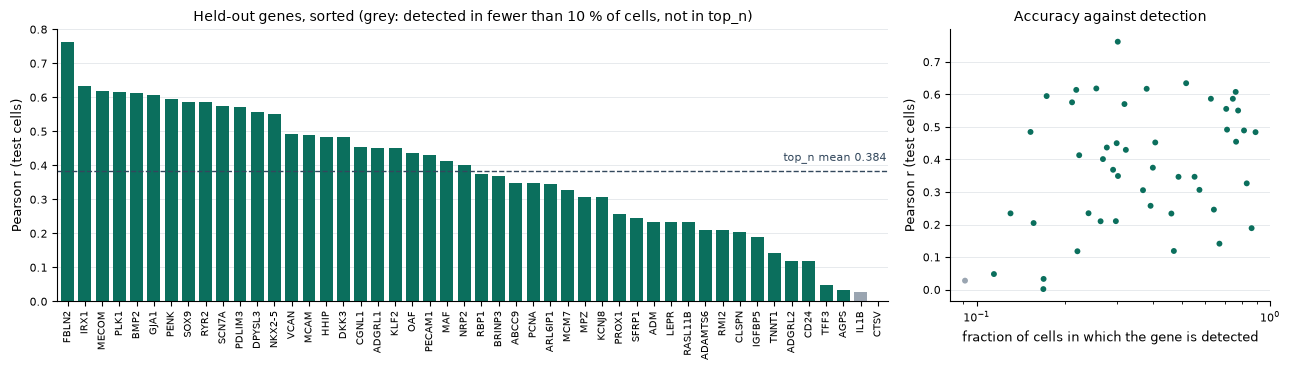

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.6, 1]})

colors = [TEAL if t else "#9aa5b1" for t in per_gene["in top_n"]]
pos = np.arange(len(per_gene))
ax1.bar(pos, per_gene["pearson"], width=0.75, color=colors)
mean_top = scores["top_n"]["pearson"]
ax1.axhline(mean_top, color="#33485d", lw=1, ls="--")
ax1.text(len(per_gene) - 0.5, mean_top + 0.02, f"top_n mean {mean_top:.3f}", ha="right", va="bottom", fontsize=8,
         color="#33485d")
ax1.set_xticks(pos, per_gene.index, rotation=90, fontsize=7)
ax1.set_xlim(-0.6, len(per_gene) - 0.4)
ax1.set_ylabel("Pearson r (test cells)")
ax1.set_title("Held-out genes, sorted (grey: detected in fewer than 10 % of cells, not in top_n)")

ax2.scatter(per_gene["fraction of cells detected"], per_gene["pearson"], s=18, c=colors, linewidths=0)
ax2.set_xscale("log")
ax2.set_xlabel("fraction of cells in which the gene is detected")
ax2.set_ylabel("Pearson r (test cells)")
ax2.set_title("Accuracy against detection")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e3e6ea", lw=0.6)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In this sample the score depends only loosely on how often a gene is detected (right panel).

## 5. Measured and predicted maps

The held-out genes were hidden from the model in every cell, so we can draw measured and predicted values over the whole
window. We show four of the scored genes picked by rank, not by eye: the best, the one at the first quartile, the median
and the worst. Each map has its own colour scale, from its 1st to its 99th percentile.

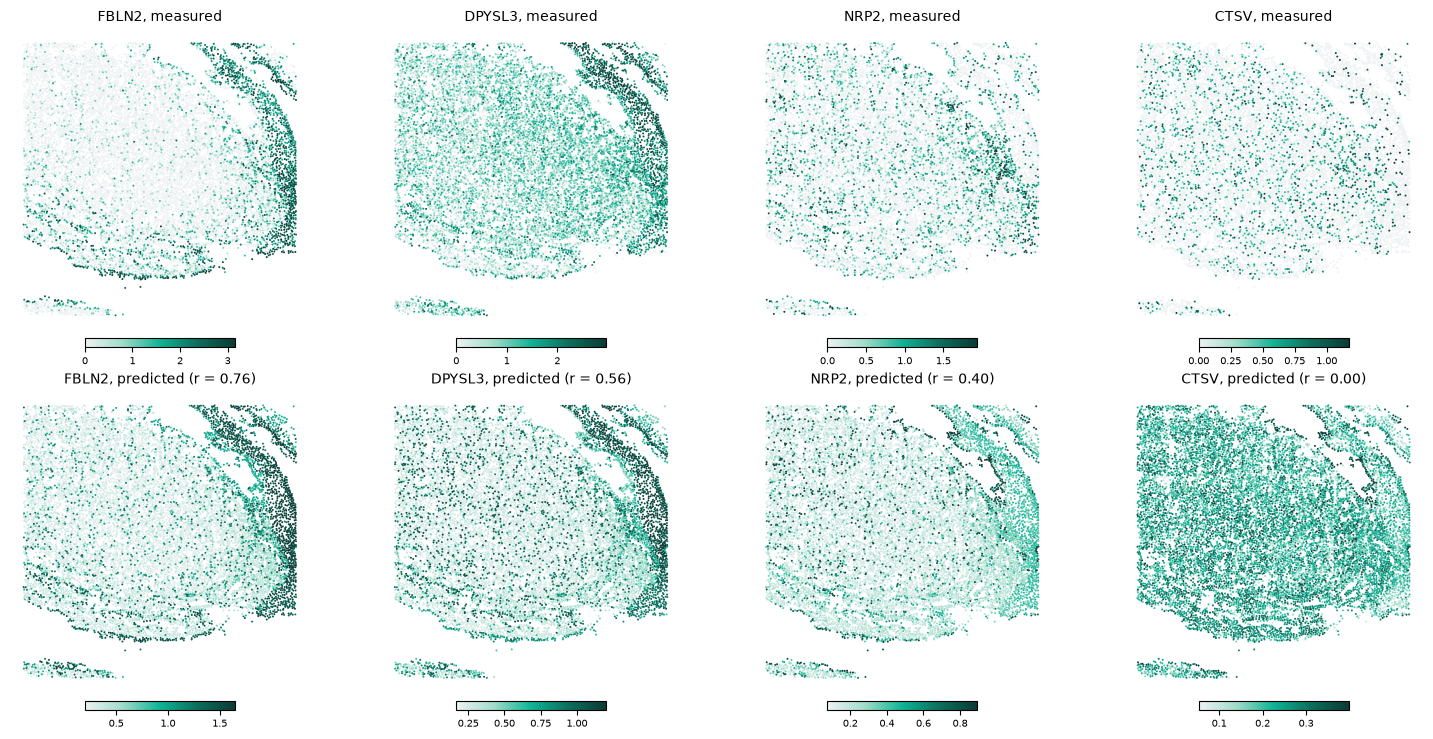

In [15]:
from resonate.metrics import truth_log_expression

truth = pd.DataFrame(truth_log_expression(prep), columns=truth_genes)   # measured values, log scale


def expression_map(ax, values, title):
    values = np.asarray(values, dtype=float)
    lo, hi = np.percentile(values, [1, 99])
    order = np.argsort(values)                                           # high values drawn on top
    points = ax.scatter(xy[order, 0], xy[order, 1], c=values[order], s=2.0, cmap=RAMP, vmin=lo, vmax=hi,
                        linewidths=0)
    ax.set_title(title)
    clean(ax)
    bar = plt.colorbar(points, cax=ax.inset_axes([0.25, -0.06, 0.5, 0.03]), orientation="horizontal")
    bar.ax.tick_params(labelsize=7)


ranked = per_gene[per_gene["in top_n"]]
show = list(ranked.index[[0, len(ranked) // 4, len(ranked) // 2, len(ranked) - 1]])

fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
for j, g in enumerate(show):
    expression_map(axes[0, j], truth[g], f"{g}, measured")
    expression_map(axes[1, j], pred[:, g].X.ravel(), f"{g}, predicted (r = {per_gene.loc[g, 'pearson']:.2f})")
fig.tight_layout()
plt.show()

The colour bars show that the predictions span a narrower range than the measurements: the model is fitted to agree
with the measured values across cells, not to reproduce their spread. Compare patterns, not absolute levels.

*FBLN2*, the best-predicted gene, is concentrated on the right of the window and along its lower edge in both maps.
*CTSV*, the worst, is measured in scattered cells without a clear pattern, and its prediction does not follow it
(r = 0.00).

## 6. Predict genes outside the panel

In real use, the genes you want were never measured in the spatial data. The fitted model predicts any gene that the
reference measures and that has an embedding, without refitting: pass the reference and the embeddings to `predict`.

We take marker genes of the main cell groups that the reference measures and the panel does not. *NPPA* and *NPPB*
(natriuretic peptides) are known markers of trabecular ventricular cardiomyocytes in the developing heart; *MYL2*,
*MYL3* and *FHL2* mark ventricular cardiomyocytes; *OGN*, *COL6A2* and *MFAP4* fibroblasts; *CDH5*, *EGFL7* and *EMCN*
endothelial cells; *NDUFA4L2* and *COX4I2* pericytes and smooth muscle cells. These genes were picked from the
reference's marker genes before looking at any prediction.

In [16]:
markers = {
    "cardiomyocyte": ["NPPA", "NPPB", "MYL2", "MYL3", "FHL2"],
    "fibroblast": ["OGN", "COL6A2", "MFAP4"],
    "endothelial": ["CDH5", "EGFL7", "EMCN"],
    "pericyte / SMC": ["NDUFA4L2", "COX4I2"],
}
genes = [g for gs in markers.values() for g in gs]

ref_counts = reference[:, genes].X
ref_counts = ref_counts.toarray() if hasattr(ref_counts, "toarray") else np.asarray(ref_counts)
pd.DataFrame({
    "in the spatial panel": [g in panel for g in genes],
    "in the reference": [g in reference.var_names for g in genes],
    "has an embedding": [emb.has(g) for g in genes],
    "fraction of reference cells detected": (ref_counts > 0).mean(0).round(3),
}, index=genes)

,in the spatial panel,in the reference,has an embedding,fraction of reference cells detected
NPPA,False,True,True,0.748
NPPB,False,True,True,0.194
MYL2,False,True,True,0.363
MYL3,False,True,True,0.483
FHL2,False,True,True,0.558
OGN,False,True,True,0.430
COL6A2,False,True,True,0.582
MFAP4,False,True,True,0.522
CDH5,False,True,True,0.075
EGFL7,False,True,True,0.277


In [17]:
t0 = time.time()
unseen = model.predict(genes, reference=reference, gene_embeddings=emb)
print(f"predicted {unseen.n_vars} genes in {unseen.n_obs:,} cells in {time.time() - t0:.0f} s")
unseen

predicted 13 genes in 12,000 cells in 4 s


AnnData object with n_obs × n_vars = 12000 × 13
    obs: 'split'
    var: 'is_fit_target'
    uns: 'resonate'
    obsm: 'spatial'

`var["is_fit_target"]` is `False` for all of them: none was a target during training. Genes that the panel measures
are inputs of the model and cannot be requested:

In [18]:
try:
    model.predict(["HEY2"], reference=reference, gene_embeddings=emb)
except ValueError as err:
    print("ValueError:", err)

ValueError: 1 requested genes are measured in the spatial panel and are model inputs (e.g. ['HEY2']); predict unmeasured genes, or hold the gene out with prepare(target_genes=...)


For an analysis of your own data, keep every measured gene as input and list the genes you care about as targets:
`resonate.prepare(spatial, reference, emb, target_genes=[...genes outside the panel...])`, then `fit` and `predict`.
Here we reuse the model fitted in step 3, which had the 48 held-out genes removed from its input.

Below, top row: predicted expression of one marker per group. Bottom row: the cells that the authors assigned to the
matching group.

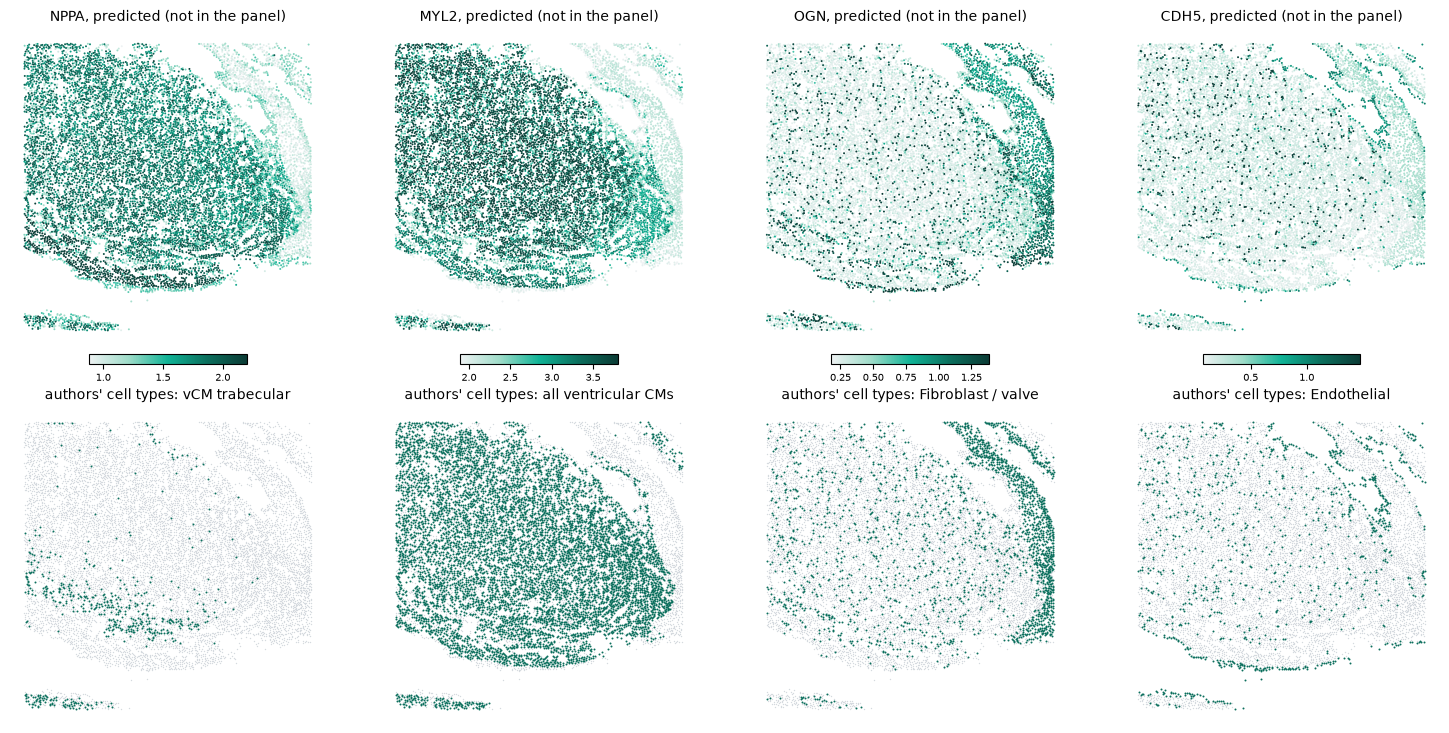

In [19]:
pairs = [("NPPA", "vCM trabecular"), ("MYL2", None), ("OGN", "Fibroblast / valve"), ("CDH5", "Endothelial")]
vcm = spatial.obs["group"].astype(str).str.startswith("vCM").to_numpy()

fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
for j, (g, grp) in enumerate(pairs):
    expression_map(axes[0, j], unseen[:, g].X.ravel(), f"{g}, predicted (not in the panel)")
    m = vcm if grp is None else (spatial.obs["group"] == grp).to_numpy()
    axes[1, j].scatter(xy[~m, 0], xy[~m, 1], s=1.0, c=GREY, linewidths=0)
    axes[1, j].scatter(xy[m, 0], xy[m, 1], s=2.0, c=TEAL, linewidths=0)
    axes[1, j].set_title(f"authors' cell types: {grp or 'all ventricular CMs'}")
    clean(axes[1, j])
fig.tight_layout()
plt.show()

Predicted *MYL2* is high in the ventricular cardiomyocytes and low on the right of the window, where the authors'
fibroblast and valve cells lie; predicted *OGN* is highest there. Predicted *CDH5* is highest in scattered cells and along
the lower edge, as are the authors' endothelial cells. Predicted *NPPA* is high across the ventricular cardiomyocytes,
not only in the trabecular cells; step 7 compares the groups.

## 7. Predicted expression by cell type

The spatial data cannot score these genes, but the reference measures them. On the left, the mean predicted expression
of each marker in each group of spatial cells; on the right, the mean measured expression in each cell type of the
reference (`log1p` of counts per 10,000). The two sides use different cell-type labels and different scales, so each row
is scaled from its lowest to its highest group mean.

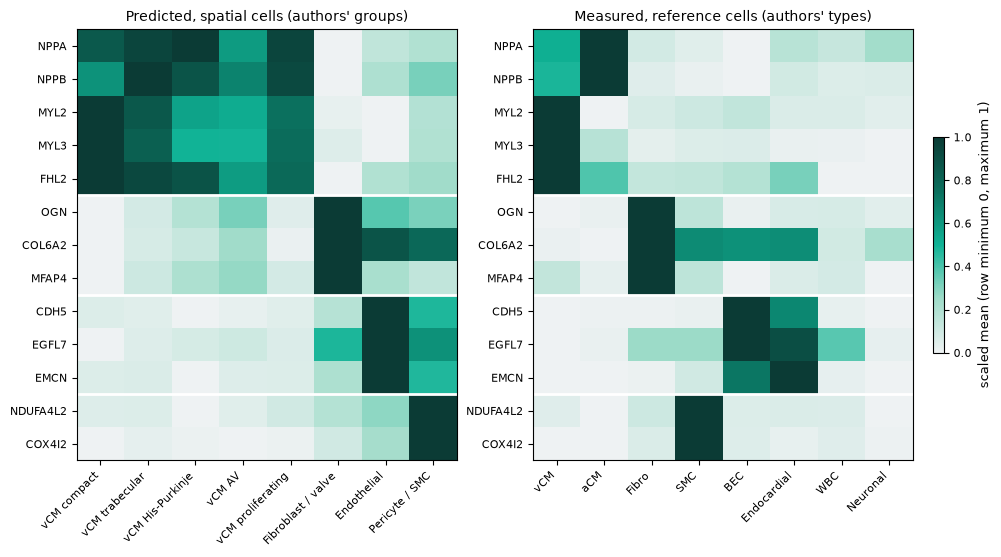

In [20]:
pred_means = unseen.to_df().groupby(spatial.obs["group"].to_numpy()).mean().loc[list(GROUPS)].T

ref_types = ["vCM", "aCM", "Fibro", "SMC", "BEC", "Endocardial", "WBC", "Neuronal"]
ref_means = sc.get.obs_df(ref_log, keys=genes + ["author_label"]).groupby("author_label", observed=True).mean()
ref_means = ref_means.loc[ref_types].T


def scaled(df):
    lo, hi = df.min(axis=1), df.max(axis=1)
    return df.sub(lo, axis=0).div((hi - lo).replace(0, 1), axis=0)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [len(GROUPS), len(ref_types)]})
for ax, df, title in [(axes[0], pred_means, "Predicted, spatial cells (authors' groups)"),
                      (axes[1], ref_means, "Measured, reference cells (authors' types)")]:
    im = ax.imshow(scaled(df).to_numpy(), cmap=RAMP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=45, ha="right")
    ax.set_yticks(range(df.shape[0]), df.index)
    ax.set_title(title)
    for k in np.cumsum([len(v) for v in markers.values()])[:-1]:
        ax.axhline(k - 0.5, color="white", lw=2)
plt.colorbar(im, ax=axes, shrink=0.5, pad=0.02, label="scaled mean (row minimum 0, maximum 1)")
plt.show()

Scaling each row hides how large the differences are. The unscaled predicted means:

In [21]:
pred_means.round(2)

,vCM compact,vCM trabecular,vCM His-Purkinje,vCM AV,vCM proliferating,Fibroblast / valve,Endothelial,Pericyte / SMC
gene,,,,,,,,
NPPA,1.80,1.88,1.92,1.58,1.88,1.10,1.22,1.26
NPPB,1.43,1.58,1.53,1.45,1.56,1.17,1.25,1.30
MYL2,3.63,3.45,3.05,3.01,3.30,2.34,2.32,2.56
MYL3,3.51,3.27,2.85,2.85,3.19,2.26,2.19,2.45
FHL2,1.51,1.46,1.42,1.18,1.33,0.70,0.86,0.90
OGN,0.24,0.31,0.39,0.50,0.28,1.06,0.55,0.50
COL6A2,0.33,0.42,0.47,0.61,0.35,1.45,1.31,1.20
MFAP4,0.32,0.42,0.52,0.58,0.40,1.29,0.53,0.46
CDH5,0.19,0.18,0.14,0.16,0.18,0.31,1.08,0.58


For each of the 13 markers, the group of spatial cells with the highest predicted mean is the group that matches the
reference: cardiomyocyte genes in the ventricular cardiomyocyte groups, fibroblast genes in the fibroblast and valve
cells, endothelial genes in the endothelial cells and the two pericyte genes in the pericytes and smooth muscle cells.
Every gene keeps a baseline in the other groups: predicted *NPPA* is 1.10 to 1.26 outside the cardiomyocytes and 1.58
to 1.92 inside them.

**Within the ventricular cardiomyocytes.** In the developing heart, the trabecular myocardium expresses *NPPA* and
*NPPB*, and the compact myocardium expresses *HEY2*. *HEY2* and *IRX3* are in the panel, so their measured values show
how the authors' compact, trabecular and His-Purkinje labels differ in this section; *NPPA* and *NPPB* are predictions.

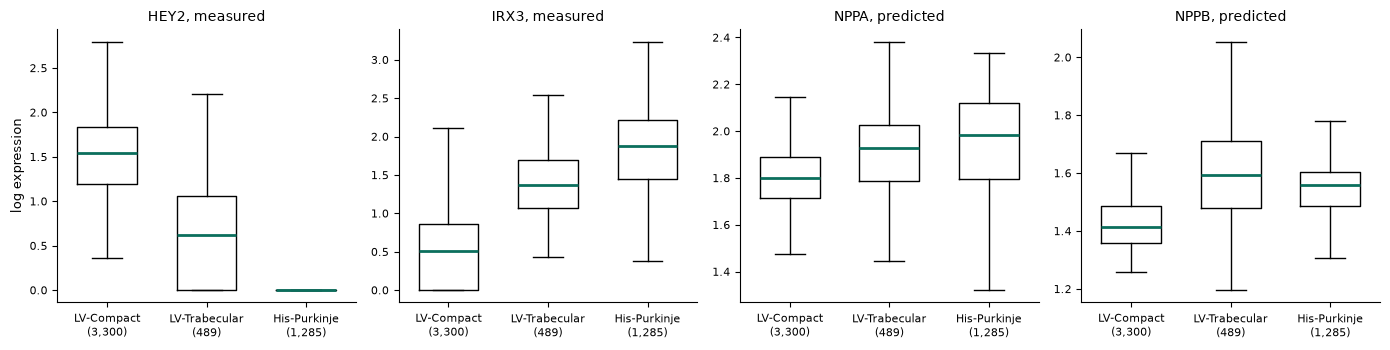

,HEY2 (measured),IRX3 (measured),NPPA (predicted),NPPB (predicted)
vCM-LV-Compact,1.486,0.493,1.804,1.428
vCM-LV-Trabecular,0.612,1.335,1.884,1.597
vCM-His-Purkinje,0.165,1.763,1.925,1.534


In [22]:
spatial_log = spatial.copy()
sc.pp.normalize_total(spatial_log)            # counts scaled to the median library size, then log1p
sc.pp.log1p(spatial_log)

subtypes = ["vCM-LV-Compact", "vCM-LV-Trabecular", "vCM-His-Purkinje"]
cells = spatial.obs["author_fine"].isin(subtypes).to_numpy()
fine = spatial.obs["author_fine"].astype(str).to_numpy()[cells]
panels = [("HEY2", "measured", spatial_log[cells, "HEY2"].X), ("IRX3", "measured", spatial_log[cells, "IRX3"].X),
          ("NPPA", "predicted", unseen[cells, "NPPA"].X), ("NPPB", "predicted", unseen[cells, "NPPB"].X)]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
table = {}
for ax, (g, kind, X) in zip(axes, panels):
    v = np.asarray(X.toarray() if hasattr(X, "toarray") else X).ravel()
    data = [v[fine == t] for t in subtypes]
    ax.boxplot(data, showfliers=False, widths=0.6, medianprops={"color": TEAL, "lw": 2})
    ax.set_xticks([1, 2, 3], [f"{t.replace('vCM-', '')}\n({len(d):,})" for t, d in zip(subtypes, data)], fontsize=8)
    ax.set_title(f"{g}, {kind}")
    ax.spines[["top", "right"]].set_visible(False)
    table[f"{g} ({kind})"] = [d.mean() for d in data]
axes[0].set_ylabel("log expression")
fig.tight_layout()
plt.show()

pd.DataFrame(table, index=subtypes).round(3)

For the measured panel genes, the authors' labels behave as expected in this section: *HEY2* is highest in compact cells
(mean 1.49 against 0.61 in trabecular cells) and *IRX3* in trabecular and His-Purkinje cells (0.49 in compact, 1.34 in
trabecular cells). Predicted *NPPA* and *NPPB* are also higher in trabecular and His-Purkinje cells than in compact cells,
the expected direction, but the differences are small: 1.88 against 1.80 for *NPPA* and 1.60 against 1.43 for *NPPB*,
next to differences of 0.84 to 0.87 for the two measured markers. Treat such differences in predicted genes as leads to
check, for example against randomly chosen predicted genes or with a measurement, not as findings.

## 8. Save the results

Predictions are AnnData objects and can be written to `.h5ad`. A fitted model is saved together with the prepared inputs
it was trained on, and reloaded from both.

In [23]:
import os

os.makedirs("results", exist_ok=True)
pred.write_h5ad("results/heldout_predictions.h5ad")
unseen.write_h5ad("results/outside_panel_predictions.h5ad")
per_gene.to_csv("results/heldout_per_gene_scores.csv")
prep.save("results/prepared")
model.save("results/model")

reloaded = resonate.Resonate.load("results/model", resonate.Prepared.load("results/prepared"), device="cpu")
again = reloaded.predict(genes, reference=reference, gene_embeddings=emb)
print("same predictions after reloading:", np.allclose(again.X, unseen.X, atol=1e-5))
for root, _, files in sorted(os.walk("results")):
    for f in sorted(files):
        path = os.path.join(root, f)
        print(f"{os.path.getsize(path) / 1e6:8.1f} MB  {path}")

same predictions after reloading: True
     0.0 MB  results/heldout_per_gene_scores.csv
     3.0 MB  results/heldout_predictions.h5ad
     1.3 MB  results/outside_panel_predictions.h5ad
     0.0 MB  results/model/model.json
     8.8 MB  results/model/model.pt
   107.2 MB  results/prepared/arrays.npz
     0.0 MB  results/prepared/meta.json


The prepared inputs take about 107 MB on disk and the model about 9 MB.

## Next steps

* Run the same steps from a shell: [Command line](https://j041120h.github.io/RESONATE_tutorial/tutorials/cli/).
* Use your own data: [Inputs and outputs](https://j041120h.github.io/RESONATE_tutorial/tutorials/inputs_outputs/) and
  [Choosing a reference and gene embeddings](https://j041120h.github.io/RESONATE_tutorial/tutorials/choosing/).
* All arguments: [API reference](https://j041120h.github.io/RESONATE_tutorial/api/).